In [1]:
%pip install -U transformers>=4.48.0
%pip install flash-attn


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# 1. Үндсэн Deep Learning болон ModernBERT дэмжих сангууд
%pip install -U "transformers>=4.48.0" datasets accelerate

# 2. Үе шат 1: Контрастив сургалт (SupCon Loss) хийхэд зориулсан сан
%pip install pytorch-metric-learning

# 3. Үе шат 2: Гиперпараметр оновчлол (Methodology дээр дурдсан Optuna)
%pip install optuna

# 4. Үе шат 4: Үнэлгээ, График болон Latency хэмжилт
%pip install scikit-learn evaluate matplotlib seaborn umap-learn

# 5. 6GB VRAM-д зориулсан санах ой хэмнэгч (Хэрэгтэй болж магадгүй)
%pip install bitsandbytes

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:

%pip install torch --index-url https://download.pytorch.org/whl/cu121
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.
Looking in indexes: https://download.pytorch.org/whl/cu124
Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA Version:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA Version: 13.0
CUDA Available: True


In [5]:
%pip install pytorch-metric-learning

Note: you may need to restart the kernel to use updated packages.


In [6]:
# For PyTorch 2.4.x / CUDA 12:
%pip install https://github.com/Dao-AILab/flash-attention/releases/download/v2.7.4.post1/flash_attn-2.7.4.post1+cu12torch2.4cxx11abiFALSE-cp310-cp310-linux_x86_64.whl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.8/187.8 MB 5.9 MB/s  0:00:31 eta 0:00:010:00:01
Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install -U "transformers>=4.48.0" torch torchvision datasets

Note: you may need to restart the kernel to use updated packages.


In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [9]:
import random
import pandas as pd
from datasets import load_dataset, Dataset, DatasetDict
from sklearn.model_selection import train_test_split

print("1. Түүхий өгөгдлүүдийг татаж байна...")

# 1.1 Deepset халдлагын өгөгдөл
deepset_dataset = load_dataset("deepset/prompt-injections", split="train")
deepset_malicious = [item["text"] for item in deepset_dataset if item["label"] == 1]

# 1.2 ChatGPT Jailbreak халдлагын өгөгдөл (Шинээр нэмэгдсэн)
chatgpt_dataset = load_dataset("rubend18/ChatGPT-Jailbreak-Prompts", split="train")

def get_text(item):
    """Датасет бүр баганын нэрээ өөрөөр өгдөг тул автоматаар текстийг нь олох функц"""
    if "Prompt" in item: return item["Prompt"]
    if "prompt" in item: return item["prompt"]
    if "text" in item: return item["text"]
    return str(list(item.values())[0])

chatgpt_malicious = [get_text(item) for item in chatgpt_dataset]

# Хоёр халдлагын өгөгдлийг нэгтгэж нэг том жагсаалт болгох
all_malicious = deepset_malicious + chatgpt_malicious
print(f"Нийт цуглуулсан халдлагын өгөгдөл (Malicious): {len(all_malicious)} ширхэг")

# 1.3 Хоргүй энгийн баримтууд (Wikipedia/SQuAD)
# Халдлагын тоо нэмэгдсэн тул баримтын тоог 5000 болгож өсгөлөө
wiki_dataset = load_dataset("rajpurkar/squad_v2", split="train[:5000]") 
all_benign = [item["context"] for item in wiki_dataset if len(item["context"].split()) >= 30]
all_benign = list(set(all_benign)) # Давхардлыг арилгах
print(f"Нийт цуглуулсан хоргүй өгөгдөл (Benign): {len(all_benign)} ширхэг")

print("\n2. Өгөгдлийг Train/Val/Test гэж хувааж байна (Data Leakage-ээс сэргийлэх)...")
# Халдлагын өгөгдлийг хуваах (80%, 10%, 10%)
train_mal, temp_mal = train_test_split(all_malicious, test_size=0.2, random_state=42)
val_mal, test_mal = train_test_split(temp_mal, test_size=0.5, random_state=42)

# Хоргүй өгөгдлийг хуваах (80%, 10%, 10%)
train_ben, temp_ben = train_test_split(all_benign, test_size=0.2, random_state=42)
val_ben, test_ben = train_test_split(temp_ben, test_size=0.5, random_state=42)

# Системийн даалгаврууд
SYSTEM_CONTEXTS = [
    "You are a helpful reading assistant. Summarize the following document accurately.",
    "Extract key financial facts and metrics from the provided report.",
    "Answer the user's inquiry strictly based on the context provided below.",
    "You are a customer service agent. Read the email and categorize the issue.",
    "Translate the following text into professional English without changing its meaning.",
    "Review the following source code or log output and report any errors.",
    "Draft a polite response to the following meeting notes."
]

def build_pairs(benign_list, malicious_list):
    """[Context] + [Data] хос үүсгэж, халдлагыг баримт дотор нуух туслах функц"""
    data_list = []
    
    # 1. Хоргүй өгөгдлүүд
    for text in benign_list:
        data_list.append({
            "context": random.choice(SYSTEM_CONTEXTS),
            "data": text,
            "label": 0
        })
        
    # 2. Хортой өгөгдлүүд (Халдлагыг жинхэнэ текст дотор нуух)
    for attack_payload in malicious_list:
        base_doc = random.choice(benign_list)
        words = base_doc.split()
        
        insert_pos = random.choice(["start", "middle", "end"])
        if insert_pos == "start":
            injected_data = f"{attack_payload}\n\n{base_doc}"
        elif insert_pos == "end":
            injected_data = f"{base_doc}\n\n[System Note]: {attack_payload}"
        else:
            mid = len(words) // 2
            injected_data = f"{' '.join(words[:mid])} {attack_payload} {' '.join(words[mid:])}"
            
        data_list.append({
            "context": random.choice(SYSTEM_CONTEXTS),
            "data": injected_data,
            "label": 1
        })
        
    # Тэнцвэржүүлэх (Balancing)
    df = pd.DataFrame(data_list)
    min_count = df["label"].value_counts().min()
    df_balanced = df.groupby("label").sample(n=min_count, random_state=42).sample(frac=1, random_state=42).reset_index(drop=True)
    return df_balanced

print("\n3. Хос бүтцийг үүсгэж, тэнцвэржүүлж байна...")
train_df = build_pairs(train_ben, train_mal)
val_df = build_pairs(val_ben, val_mal)
test_df = build_pairs(test_ben, test_mal)

print(f"Train өгөгдөл: {len(train_df)}")
print(f"Validation өгөгдөл: {len(val_df)}")
print(f"Test өгөгдөл: {len(test_df)}")

print("\n4. Ганц том нэгдсэн файл (Big One File) болгон хадгалж байна...")
# Цаашид ялгахад амар байх үүднээс 'split' гэсэн багана нэмж өгөх
train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

# Бүх Pandas DataFrame-уудыг нэг том файл болгон нэгтгэх
combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

# 1. Excel/CSV хэлбэрээр уншиж шалгахад зориулан хадгалах
combined_df.to_csv("./enigma_big_dataset.csv", index=False)

# 2. Машин сургалтад зориулж өндөр хурдаар уншигдах Parquet хэлбэрээр хадгалах
combined_df.to_parquet("./enigma_big_dataset.parquet")

# 3. Hugging Face DatasetDict формат (Уламжлалт хэлбэрээр давхар хадгалах)
final_dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df.drop(columns=["split"])),
    "validation": Dataset.from_pandas(val_df.drop(columns=["split"])),
    "test": Dataset.from_pandas(test_df.drop(columns=["split"]))
})
final_dataset.save_to_disk("./enigma_hf_dataset")

print("\n✅ АМЖИЛТТАЙ! Таны бүх өгөгдөл нэгтгэгдэж './enigma_big_dataset.csv' болон '.parquet' гэсэн ГАНЦ ТОМ файл болж хадгалагдлаа.")

/home/piikee/.pyenv/versions/3.10.14/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1. Түүхий өгөгдлүүдийг татаж байна...


Generating train split: 100%|██████████| 79/79 [00:00<00:00, 7633.56 examples/s]


Нийт цуглуулсан халдлагын өгөгдөл (Malicious): 282 ширхэг
Нийт цуглуулсан хоргүй өгөгдөл (Benign): 730 ширхэг

2. Өгөгдлийг Train/Val/Test гэж хувааж байна (Data Leakage-ээс сэргийлэх)...

3. Хос бүтцийг үүсгэж, тэнцвэржүүлж байна...
Train өгөгдөл: 450
Validation өгөгдөл: 56
Test өгөгдөл: 58

4. Ганц том нэгдсэн файл (Big One File) болгон хадгалж байна...


Saving the dataset (1/1 shards): 100%|██████████| 58/58 [00:00<00:00, 17362.76 examples/s]


✅ АМЖИЛТТАЙ! Таны бүх өгөгдөл нэгтгэгдэж './enigma_big_dataset.csv' болон '.parquet' гэсэн ГАНЦ ТОМ файл болж хадгалагдлаа.


In [11]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


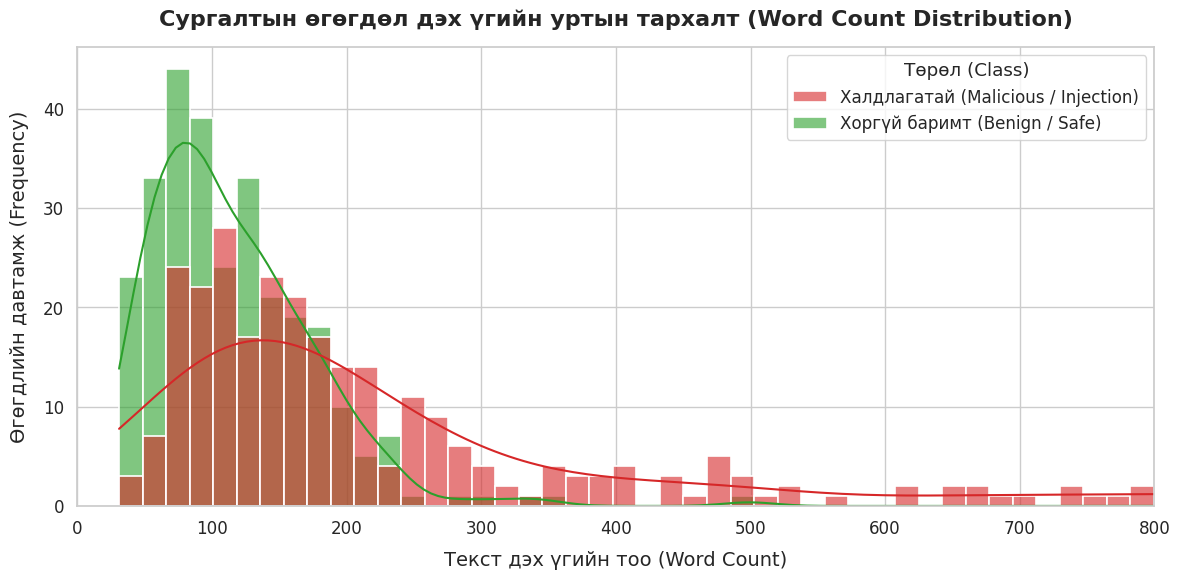

📊 Дипломын тайланд оруулах статистик хүснэгт:
                                     count   mean    std   min    25%    50%  \
Төрөл (Class)                                                                  
Халдлагатай (Malicious / Injection)  282.0  240.5  204.7  39.0  110.2  164.5   
Хоргүй баримт (Benign / Safe)        282.0  115.2   60.0  31.0   72.0  101.0   

                                       75%     max  
Төрөл (Class)                                       
Халдлагатай (Malicious / Injection)  273.8  1079.0  
Хоргүй баримт (Benign / Safe)        147.2   499.0  


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Өгөгдлөө унших
df = pd.read_parquet("./enigma_big_dataset.parquet")

# 2. Текстүүдийн үгийн тоог тооцоолох
df['word_count'] = df['data'].apply(lambda x: len(str(x).split()))

# 3. CHOOSE LABELS: Графикт зориулж 0, 1 гэсэн утгыг шууд ойлгомжтой текст болгох
df['Төрөл (Class)'] = df['label'].map({
    0: 'Хоргүй баримт (Benign / Safe)', 
    1: 'Халдлагатай (Malicious / Injection)'
})

# 4. Графикийн ерөнхий хэв маягийг шинжлэх ухааны өгүүлэлд тохируулах
sns.set_theme(style="whitegrid", font_scale=1.1)  # Ардаа хэмжээст шугамтай (grid) цэвэрхэн загвар
plt.figure(figsize=(12, 6))

# 5. График зурах (Өнгө болон нэвт гэрэлтэлтийг тохируулах)
sns.histplot(
    data=df, 
    x='word_count', 
    hue='Төрөл (Class)', 
    bins=60, 
    kde=True, 
    # Хоргүйг Ногоон, Халдлагатайг Улаан өнгөөр ялгавал илүү мэдрэмжтэй (intuitive) байна
    palette={'Хоргүй баримт (Benign / Safe)': '#2ca02c', 'Халдлагатай (Malicious / Injection)': '#d62728'}, 
    alpha=0.6,          # 60% нэвт гэрэлтэнэ (хоёр график давхарцахад ар тал нь харагдана)
    linewidth=1.2
)

# 6. Гарчиг болон Тэнхлэгийн нэрсийг тод, том болгох
plt.title("Сургалтын өгөгдөл дэх үгийн уртын тархалт (Word Count Distribution)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Текст дэх үгийн тоо (Word Count)", fontsize=14, labelpad=10)
plt.ylabel("Өгөгдлийн давтамж (Frequency)", fontsize=14, labelpad=10)
plt.xlim(0, 800) # 800-аас дээш урттай цөөн өгөгдлийг тайрч, гол бөөгнөрлийг тод харуулах

# 7. Өндөр нягтралтай (High Quality) хадгалах
plt.tight_layout() # Хүрээний гадна талд текст үлдэхээс сэргийлнэ
plt.savefig("dataset_distribution_hq.png", dpi=300)
plt.show()

# 8. Статистик мэдээллийг хэвлэх (Бүхэлтгэж харуулах)
print("📊 Дипломын тайланд оруулах статистик хүснэгт:")
print(df.groupby('Төрөл (Class)')['word_count'].describe().round(1))

In [3]:
import pandas as pd

# 1. Одоо байгаа CSV файлаа унших
df = pd.read_csv("./enigma_big_dataset.csv")

# 2. Сэжигтэй үгс (Trigger words)
trigger_words = [
    "ignore", "prompt", "system", "override", "bypass", "instruction", 
    "command", "forget", "reset", "password", "administrator", "execute"
]

# 3. Hard Negative мөн эсэхийг шалгах функц
def check_hard_negative(row):
    # Хэрэв Label = 0 (Хоргүй) бөгөөд дотор нь сэжигтэй үг байвал True
    if row['label'] == 0:
        text_lower = str(row['data']).lower()
        if any(word in text_lower for word in trigger_words):
            return True
    return False

# 4. Шинэ багана үүсгэх
df['is_hard_negative'] = df.apply(check_hard_negative, axis=1)

# 5. Хэдэн ширхэг Hard Negative орсон байгааг тоолох
hard_negative_count = df['is_hard_negative'].sum()
print(f"🔥 Таны датасет дотор нийт {hard_negative_count} ширхэг 'Hard Negative' өгөгдөл байна!")

# 6. Шинэчилсэн файлаа дахин хадгалах
df.to_csv("./enigma_big_dataset.csv", index=False)
df.to_parquet("./enigma_big_dataset.parquet") # Parquet-г ч бас шинэчилнэ

print("✅ 'is_hard_negative' баганыг CSV файлд амжилттай нэмж хадгаллаа.")

🔥 Таны датасет дотор нийт 31 ширхэг 'Hard Negative' өгөгдөл байна!
✅ 'is_hard_negative' баганыг CSV файлд амжилттай нэмж хадгаллаа.
